# SI 544 Final Project
## Predicting Vehicle Fuel Efficiency Using Multiple Linear Regression

**Course:** SI 544 — Statistics  
**University:** University of Michigan

### Research Question
How are vehicle weight, horsepower, and model year associated with
fuel efficiency (miles per gallon) in automobiles?

### Hypothesis
I expect vehicle weight and horsepower to have negative associations
with MPG, while model year will have a positive association,
after accounting for the other variables in the model.

### Dataset
- **Name:** Auto MPG Dataset
- **Source:** [Kaggle Auto MPG](https://www.kaggle.com/datasets/uciml/autompg-dataset)
- **Original observations:** 398
- **Dependent variable (Y):** MPG
- **Independent variables (X):** Weight, horsepower, and model year

### Statistical Method
Multiple Linear Regression (Ordinary Least Squares)

### Project Objective
This project examines how vehicle weight, horsepower, and model year
are associated with fuel efficiency.

The analysis will include descriptive statistics, visualizations,
regression coefficients, p-values, 95% confidence intervals,
model diagnostics, and verification checks.

## 1. Import Required Libraries

### Purpose
I will import the Python libraries needed to load, explore, visualize,
and analyze the Auto MPG dataset.

- **pandas:** Data loading and manipulation.
- **numpy:** Numerical calculations.
- **matplotlib:** Data visualization.
- **seaborn:** Statistical visualizations.
- **statsmodels:** Multiple linear regression and statistical inference.

These libraries will be used throughout the project.

In [69]:
# Import pandas for loading and organizing the dataset
import pandas as pd

# Import numpy for numerical calculations
import numpy as np

# Import matplotlib for creating graphs
import matplotlib.pyplot as plt

# Import seaborn for statistical visualizations
import seaborn as sns

# Import statsmodels for multiple linear regression
import statsmodels.api as sm

# Confirm that all libraries were imported successfully
print("All required libraries imported successfully!")

All required libraries imported successfully!


## 2. Load the Auto MPG Dataset

### Purpose
I will load the Auto MPG dataset directly from my GitHub repository
using pandas.

This approach makes the analysis reproducible because the dataset
can be accessed without manually uploading files.

### Expected Result
The dataset should contain:
- 398 observations (rows)
- 9 variables (columns)

I will display the first five rows to confirm that the dataset
was loaded correctly.

In [70]:
# Define the GitHub URL for the Auto MPG dataset
data_url = (
    "https://raw.githubusercontent.com/"
    "marufasumi/SI544-Automotive-Fuel-Efficiency/"
    "main/data/auto-mpg.csv"
)

# Load the CSV dataset into a pandas DataFrame
df = pd.read_csv(data_url)

# Display the number of rows and columns
print("Dataset shape:", df.shape)

# Display the first five observations
display(df.head())

Dataset shape: (398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


## 3. Inspect Dataset Structure

### Purpose
Before performing statistical analysis, I will examine the structure
and quality of the Auto MPG dataset.

I will check:
1. Column names and data types.
2. Missing values.
3. Duplicate observations.
4. Question-mark placeholders representing missing measurements.

This step is important because multiple linear regression requires
numerical values for MPG, weight, horsepower, and model year.

In [71]:
# Display all column names
print("Column names:")
print(df.columns.tolist())

# Display the data types and number of non-null values
print("\nDataset information:")
df.info()

# Check for missing values recognized by pandas
print("\nMissing values:")
print(df.isna().sum())

# Check for duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check for missing values represented by "?"
print("\nQuestion-mark placeholders:")
print((df.astype(str) == "?").sum())

Column names:
['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model year', 'origin', 'car name']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    object 
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car name      398 non-null    object 
dtypes: float64(3), int64(4), object(2)
memory usage: 28.1+ KB

Missing values:
mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model year      0
origin          0
car name        0
dtype: int64

Duplicate rows: 0


## 4. Data Cleaning

### Purpose
Before performing multiple linear regression, I need to prepare
the variables used in the analysis.

The horsepower column contains six missing measurements
represented by "?".

I will:
1. Create a copy of the original dataset.
2. Convert horsepower into a numerical variable.
3. Replace invalid horsepower values with NaN.
4. Remove observations with missing values in the regression variables.
5. Verify the number of observations remaining.

### Expected Result
- Original observations: 398
- Excluded observations: 6
- Final observations: 392

The original dataset will remain unchanged.

In [72]:
# Create a copy to keep the original dataset unchanged
clean_df = df.copy()

# Convert horsepower to numerical values
# The six "?" values will become NaN (missing values)
clean_df["horsepower"] = pd.to_numeric(
    clean_df["horsepower"],
    errors="coerce"
)

# Select the four variables needed for multiple linear regression
model_columns = ["mpg", "weight", "horsepower", "model year"]

# Count the original observations
original_count = len(clean_df)

# Remove observations with missing values in the selected variables
clean_df = clean_df[model_columns].dropna().copy()

# Count the remaining observations
final_count = len(clean_df)

# Calculate how many observations were excluded
excluded_count = original_count - final_count

# Display the cleaning results
print("Original observations:", original_count)
print("Excluded observations:", excluded_count)
print("Final observations:", final_count)

# Check whether any missing values remain
print("\nMissing values after cleaning:")
print(clean_df.isna().sum())

# Display the first five cleaned observations
print("\nFirst five cleaned observations:")
display(clean_df.head())

Original observations: 398
Excluded observations: 6
Final observations: 392

Missing values after cleaning:
mpg           0
weight        0
horsepower    0
model year    0
dtype: int64

First five cleaned observations:


,mpg,weight,horsepower,model year
0,18.0,3504,130.0,70
1,15.0,3693,165.0,70
2,18.0,3436,150.0,70
3,16.0,3433,150.0,70
4,17.0,3449,140.0,70


## 5. Descriptive Statistics

### Purpose
Before performing multiple linear regression, I will summarize
the characteristics of the cleaned Auto MPG dataset.

I will calculate descriptive statistics for:
- MPG (fuel efficiency)
- Weight (pounds)
- Horsepower
- Model year

The summary includes the count, mean, standard deviation,
minimum, quartiles, and maximum.

These statistics will help me understand the distribution
and variability of the variables before regression analysis.

All statistics are calculated using the 392 observations
remaining after data cleaning.

In [73]:
# Select the four variables used in multiple linear regression
variables = ["mpg", "weight", "horsepower", "model year"]

# Calculate descriptive statistics for the cleaned dataset
descriptive_stats = clean_df[variables].describe()

# Display the descriptive statistics rounded to two decimal places
print("Descriptive Statistics for the Auto MPG Dataset:")
display(descriptive_stats.round(2))

# Display the number of observations used in the analysis
print(f"\nTotal observations analyzed: {len(clean_df)}")

Descriptive Statistics for the Auto MPG Dataset:


,mpg,weight,horsepower,model year
count,392.00,392.00,392.00,392.00
mean,23.45,2977.58,104.47,75.98
std,7.81,849.40,38.49,3.68
min,9.00,1613.00,46.00,70.00
25%,17.00,2225.25,75.00,73.00
50%,22.75,2803.50,93.50,76.00
75%,29.00,3614.75,126.00,79.00
max,46.60,5140.00,230.00,82.00



Total observations analyzed: 392


## 6. Exploratory Data Visualization

### 6.1 Relationship Between Vehicle Weight and MPG

### Purpose
I will create a scatterplot to explore the relationship between
vehicle weight and fuel efficiency.

- X-axis: Vehicle weight (pounds)
- Y-axis: Fuel efficiency (MPG)
- Each point represents one automobile.

I expect to observe a negative relationship, meaning that
heavier vehicles tend to have lower fuel efficiency.

This visualization will help me examine the direction and
general pattern of the relationship before fitting the
multiple linear regression model.

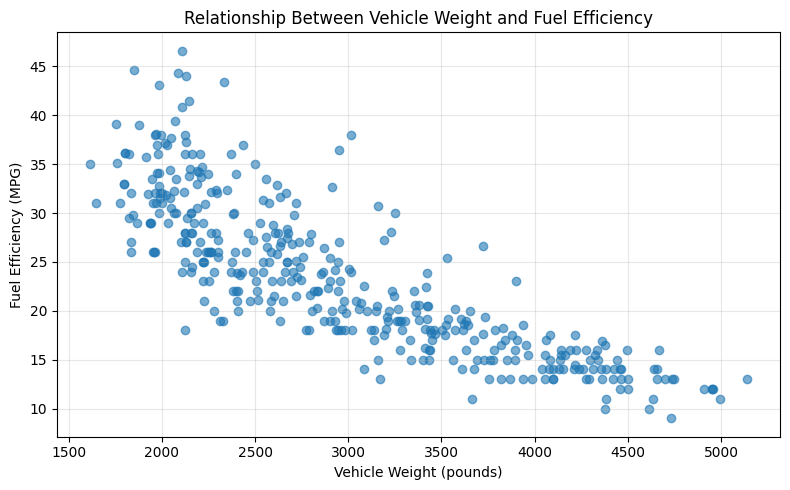

In [74]:
# Create a scatterplot of vehicle weight versus MPG
plt.figure(figsize=(8, 5))

# Plot each automobile as a point
plt.scatter(
    clean_df["weight"],
    clean_df["mpg"],
    alpha=0.6
)

# Add a descriptive title
plt.title("Relationship Between Vehicle Weight and Fuel Efficiency")

# Label the horizontal axis
plt.xlabel("Vehicle Weight (pounds)")

# Label the vertical axis
plt.ylabel("Fuel Efficiency (MPG)")

# Add gridlines to improve readability
plt.grid(True, alpha=0.3)

# Adjust spacing and display the plot
plt.tight_layout()
plt.show()

### Interpretation

The scatterplot shows a strong negative relationship between
vehicle weight and fuel efficiency.

Lighter vehicles generally have higher MPG, while heavier
vehicles tend to have lower MPG.

The relationship appears approximately linear, although some
variation and possible unusual observations are visible.

This finding provides preliminary support for my hypothesis
that vehicle weight is negatively associated with MPG.

However, this visualization does not account for horsepower
or model year. Multiple linear regression will be used to
examine the relationship while controlling for these variables.

### 6.2 Relationship Between Horsepower and MPG

### Purpose
I will create a scatterplot to examine the relationship between
engine horsepower and fuel efficiency.

- X-axis: Engine horsepower
- Y-axis: Fuel efficiency (MPG)
- Each point represents one automobile.

I expect vehicles with higher horsepower to generally have
lower MPG.

This visualization will help me examine the direction,
strength, and pattern of the relationship before regression.

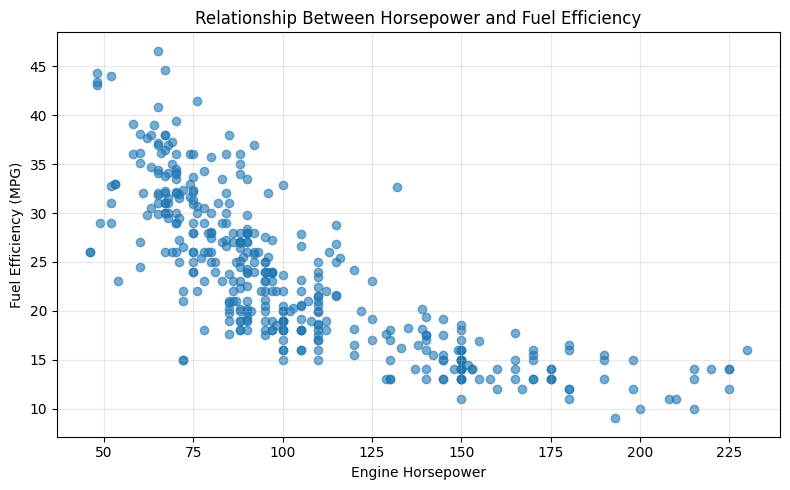

In [75]:
# Create a scatterplot of horsepower versus MPG
plt.figure(figsize=(8, 5))

# Plot each automobile using horsepower and MPG
plt.scatter(
    clean_df["horsepower"],
    clean_df["mpg"],
    alpha=0.6
)

# Add a descriptive title
plt.title("Relationship Between Horsepower and Fuel Efficiency")

# Label the horizontal axis
plt.xlabel("Engine Horsepower")

# Label the vertical axis
plt.ylabel("Fuel Efficiency (MPG)")

# Add gridlines for readability
plt.grid(True, alpha=0.3)

# Adjust spacing and display the plot
plt.tight_layout()
plt.show()

### Interpretation

The scatterplot shows a clear negative relationship between
engine horsepower and fuel efficiency.

Vehicles with lower horsepower generally achieve higher MPG,
while vehicles with higher horsepower tend to have lower MPG.

The relationship appears relatively strong, although some
curvature and variation are visible.

This finding provides preliminary support for my hypothesis
that horsepower is negatively associated with MPG.

However, the scatterplot does not account for vehicle weight
or model year. Multiple linear regression will help examine
the association while controlling for these variables.

### 6.3 Relationship Between Model Year and MPG

### Purpose
I will create a scatterplot to examine the relationship between
vehicle model year and fuel efficiency.

- X-axis: Model year (1970–1982)
- Y-axis: Fuel efficiency (MPG)
- Each point represents one automobile.

I expect newer vehicles to generally have higher MPG.

This visualization will help me examine whether fuel efficiency
improved across model years before fitting the multiple
linear regression model.

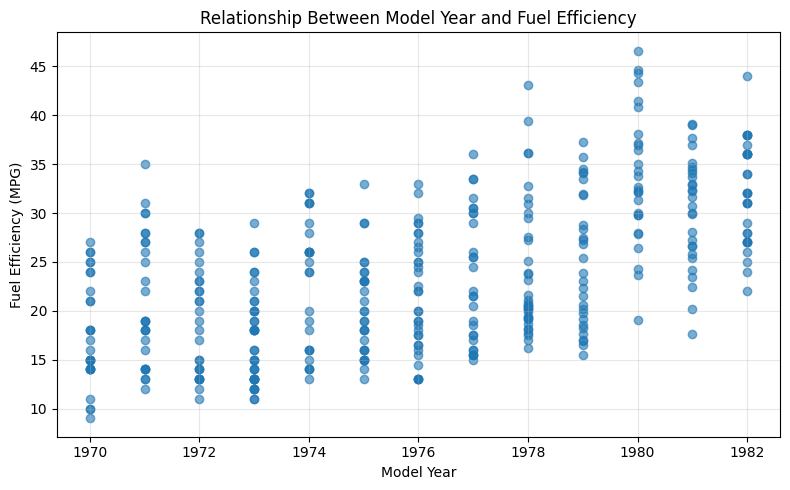

In [76]:
# Create a scatterplot of model year versus MPG
plt.figure(figsize=(8, 5))

# Plot each automobile using model year and MPG
plt.scatter(
    clean_df["model year"] + 1900,
    clean_df["mpg"],
    alpha=0.6
)

# Add a descriptive title
plt.title("Relationship Between Model Year and Fuel Efficiency")

# Label the horizontal axis
plt.xlabel("Model Year")

# Label the vertical axis
plt.ylabel("Fuel Efficiency (MPG)")

# Display the actual model years on the horizontal axis
plt.xticks(range(1970, 1983, 2))

# Add gridlines for readability
plt.grid(True, alpha=0.3)

# Adjust spacing and display the plot
plt.tight_layout()
plt.show()

### Interpretation

The scatterplot shows a positive relationship between model year
and fuel efficiency.

Newer automobiles generally have higher MPG compared with older
automobiles in the dataset.

However, there is considerable variation in MPG within each
model year, suggesting that model year alone does not fully
explain fuel efficiency.

The vertical groups of observations occur because model year
is recorded as a whole number.

This finding provides preliminary support for my hypothesis
that newer vehicles tend to have higher MPG.

Multiple linear regression will help examine this relationship
while controlling for vehicle weight and horsepower.

## 7. Correlation Analysis

### Purpose
I will calculate Pearson correlation coefficients to examine
the direction and strength of linear relationships among
MPG, vehicle weight, horsepower, and model year.

Pearson correlation ranges from -1 to +1:

- Positive values indicate positive linear relationships.
- Negative values indicate negative linear relationships.
- Values near zero indicate weak linear relationships.

I expect:
1. Weight and MPG to have a negative correlation.
2. Horsepower and MPG to have a negative correlation.
3. Model year and MPG to have a positive correlation.

I will also examine correlations among the independent
variables to identify possible multicollinearity.

Correlation does not establish causation.

In [77]:
# Select the variables used in multiple linear regression
variables = ["mpg", "weight", "horsepower", "model year"]

# Calculate the Pearson correlation matrix
correlation_matrix = clean_df[variables].corr(method="pearson")

# Display correlation coefficients rounded to three decimal places
print("Pearson Correlation Matrix:")
display(correlation_matrix.round(3))

Pearson Correlation Matrix:


,mpg,weight,horsepower,model year
mpg,1.000,-0.832,-0.778,0.581
weight,-0.832,1.000,0.865,-0.309
horsepower,-0.778,0.865,1.000,-0.416
model year,0.581,-0.309,-0.416,1.000


### Interpretation

The Pearson correlation analysis shows that vehicle weight
(r = -0.832) and horsepower (r = -0.778) have strong negative
linear relationships with MPG.

Model year has a moderate positive correlation with MPG
(r = 0.581), suggesting that newer automobiles generally
have better fuel efficiency.

These findings provide preliminary support for my hypotheses.

However, weight and horsepower are also strongly positively
correlated (r = 0.865). This suggests possible multicollinearity,
which may affect the interpretation of individual regression
coefficients.

I will examine multicollinearity using the Variance Inflation
Factor (VIF) during regression diagnostics.

Correlation does not establish causation.

## 8. Correlation Heatmap

### Purpose

I will create a correlation heatmap to visualize the
relationships among MPG, weight, horsepower, and model year.

The heatmap displays Pearson correlation coefficients
using colors:

- Blue represents negative correlations.
- Red represents positive correlations.
- Lighter colors represent correlations closer to zero.

This visualization will help identify strong relationships
between MPG and the predictors, as well as possible
multicollinearity among the independent variables.

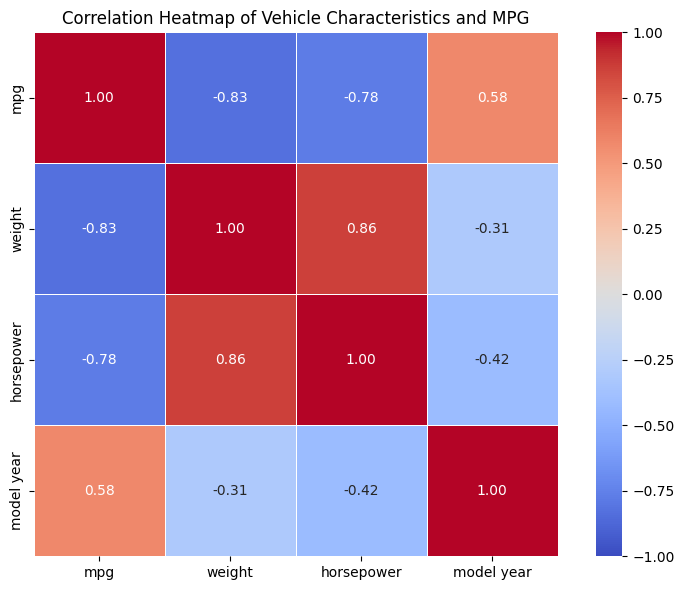

In [78]:
# Create a figure for the correlation heatmap
plt.figure(figsize=(8, 6))

# Create the heatmap using the correlation matrix
sns.heatmap(
    correlation_matrix,
    annot=True,          # Display correlation values
    fmt=".2f",           # Round values to two decimal places
    cmap="coolwarm",     # Blue = negative, red = positive
    vmin=-1,             # Minimum possible correlation
    vmax=1,              # Maximum possible correlation
    center=0,            # Center the color scale at zero
    square=True,         # Display square cells
    linewidths=0.5       # Add borders between cells
)

# Add a descriptive title
plt.title("Correlation Heatmap of Vehicle Characteristics and MPG")

# Adjust spacing and display the heatmap
plt.tight_layout()
plt.show()

## 9. Multiple Linear Regression

### Purpose
I will use multiple linear regression to examine how vehicle
weight, horsepower, and model year are associated with fuel
efficiency (MPG).

### Regression Variables
- Dependent variable (Y): MPG
- Independent variable (X1): Weight
- Independent variable (X2): Horsepower
- Independent variable (X3): Model year

### Regression Model

MPG = β0 + β1(Weight) + β2(Horsepower) + β3(Model Year) + ε

### Statistical Method
I will use Ordinary Least Squares (OLS) regression.

OLS estimates regression coefficients by minimizing the sum
of squared differences between observed and predicted MPG.

### Research Hypotheses
- Weight will have a negative coefficient.
- Horsepower will have a negative coefficient.
- Model year will have a positive coefficient.

I will examine the regression output to evaluate these hypotheses.

In [79]:
# Define the dependent variable (Y)
# MPG is the outcome we want to explain
y = clean_df["mpg"]

# Define the independent variables (X)
# These are the three vehicle characteristics
X = clean_df[["weight", "horsepower", "model year"]]

# Add a constant term for the regression intercept (β0)
X = sm.add_constant(X)

# Fit the multiple linear regression model using OLS
model = sm.OLS(y, X).fit()

# Display the complete regression results
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                    mpg   R-squared:                       0.808
Model:                            OLS   Adj. R-squared:                  0.807
Method:                 Least Squares   F-statistic:                     545.4
Date:                Wed, 25 Nov 2026   Prob (F-statistic):          9.37e-139
Time:                        17:46:50   Log-Likelihood:                -1037.4
No. Observations:                 392   AIC:                             2083.
Df Residuals:                     388   BIC:                             2099.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -13.7194      4.182     -3.281      0.0

### Interpretation of Multiple Linear Regression

The multiple linear regression model explains approximately 80.8%
of the observed variation in MPG (R-squared = 0.808).

Vehicle weight has a statistically significant negative association
with MPG (coefficient = -0.0064, p < 0.001). Holding horsepower and
model year constant, an additional 1,000 pounds of vehicle weight
is associated with approximately 6.4 fewer MPG.

Horsepower has a negative coefficient (-0.0050), but its association
is not statistically significant (p = 0.597) after controlling for
weight and model year.

Model year has a statistically significant positive association
with MPG (coefficient = 0.7487, p < 0.001). Holding the other
predictors constant, each additional model year is associated
with approximately 0.75 higher MPG.

The overall regression model is statistically significant
(F = 545.4, p < 0.001).

These findings support the hypotheses for weight and model year,
but not the hypothesis that horsepower has a statistically
significant negative coefficient in the multiple regression model.

Further diagnostics are needed to evaluate the regression
assumptions and possible multicollinearity.

## 10. Confidence Intervals for Regression Coefficients

### Purpose
I will examine the 95% confidence intervals for the
multiple linear regression coefficients.

A confidence interval provides a range of plausible values
for each population regression coefficient.

For a two-sided hypothesis test at the 0.05 significance level:

- If the 95% confidence interval excludes zero, the coefficient
  is statistically significant.
- If the 95% confidence interval includes zero, the coefficient
  is not statistically significant.

These interpretations depend on the assumptions of the
regression model.

In [80]:
# Calculate the 95% confidence intervals for regression coefficients
confidence_intervals = model.conf_int(alpha=0.05)

# Rename the columns for readability
confidence_intervals.columns = ["Lower 95% CI", "Upper 95% CI"]

# Display the confidence intervals
print("95% Confidence Intervals for Regression Coefficients:")
display(confidence_intervals.round(4))

95% Confidence Intervals for Regression Coefficients:


,Lower 95% CI,Upper 95% CI
const,-21.9411,-5.4976
weight,-0.0073,-0.0056
horsepower,-0.0236,0.0136
model year,0.6462,0.8512


### Interpretation of 95% Confidence Intervals

The 95% confidence interval for vehicle weight is
[-0.0073, -0.0056]. Because the interval does not include
zero, weight has a statistically significant negative
association with MPG after controlling for the other predictors.

The confidence interval for horsepower is
[-0.0236, 0.0136]. Because this interval includes zero,
horsepower is not statistically significant at the 0.05 level.

The confidence interval for model year is
[0.6462, 0.8512]. Because the interval is entirely positive,
model year has a statistically significant positive association
with MPG after controlling for weight and horsepower.

These confidence intervals are based on the assumptions
of the fitted OLS regression model.

## 11. Multicollinearity Analysis Using VIF

### Purpose

I will calculate the Variance Inflation Factor (VIF) to
examine multicollinearity among the independent variables.

My regression model includes three predictors:
- Vehicle weight
- Horsepower
- Model year

The correlation analysis showed a strong positive relationship
between weight and horsepower (r = 0.865).

This suggests that these predictors may contain overlapping
information.

VIF measures how much the variance of a regression coefficient
is inflated because of linear relationships with other predictors.

Higher VIF values indicate greater multicollinearity.

I will use the results to determine whether multicollinearity
may affect the interpretation of the regression coefficients.

In [81]:
# Import the function used to calculate VIF
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Select the independent variables from our regression model
predictors = ["weight", "horsepower", "model year"]

# Create a DataFrame to store VIF results
vif_data = pd.DataFrame()

# Store the predictor names
vif_data["Variable"] = predictors

# Calculate VIF for each predictor
# X already contains the intercept and all three predictors
vif_data["VIF"] = [
    variance_inflation_factor(X.values, X.columns.get_loc(variable))
    for variable in predictors
]

# Display the VIF results rounded to two decimal places
print("Variance Inflation Factor (VIF) Results:")
display(vif_data.round(2))

Variance Inflation Factor (VIF) Results:


,Variable,VIF
0,weight,4.01
1,horsepower,4.39
2,model year,1.22


### Interpretation of Multicollinearity

The VIF analysis shows that vehicle weight (VIF = 4.01)
and horsepower (VIF = 4.39) have moderate multicollinearity.

This is consistent with their strong positive correlation
(r = 0.865).

Model year has a low VIF (1.22), indicating relatively
little multicollinearity with the other predictors.

Although weight and horsepower share some overlapping
information, their VIF values are below the commonly used
threshold of 5.

Therefore, I will retain all three predictors in the
multiple linear regression model.

Multicollinearity may contribute to uncertainty in the
individual coefficient estimates, particularly horsepower.

## 12. Regression Diagnostics

### 12.1 Residuals vs. Predicted MPG

### Purpose

I will create a residual plot to evaluate whether the
multiple linear regression model adequately describes
the relationship between the predictors and MPG.

A residual is the difference between the observed MPG
and the MPG predicted by the regression model.

Residual = Actual MPG - Predicted MPG

I will plot:
- X-axis: Predicted MPG
- Y-axis: Residuals

I will examine whether the residuals are randomly
scattered around zero.

A curved pattern may indicate nonlinearity, while
changes in the spread of residuals may suggest
nonconstant error variance.

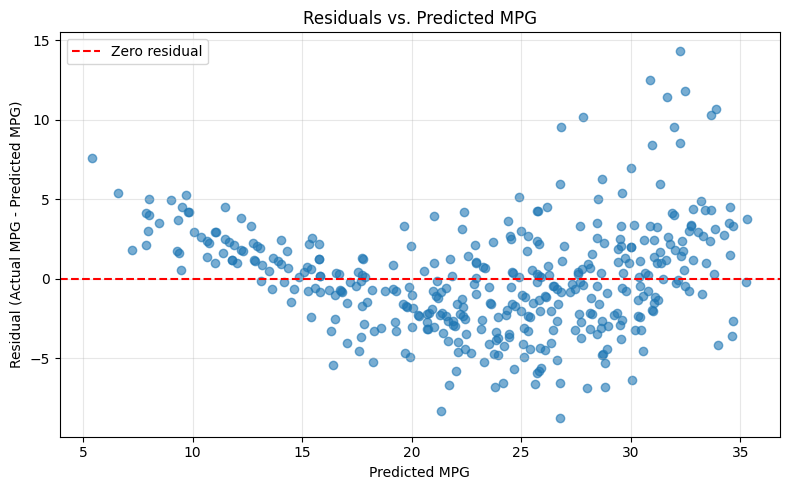

In [82]:
# Calculate predicted MPG using the fitted regression model
predicted_mpg = model.fittedvalues

# Calculate residuals (actual MPG minus predicted MPG)
residuals = model.resid

# Create a residuals versus predicted MPG scatterplot
plt.figure(figsize=(8, 5))

# Plot predicted MPG against residuals
plt.scatter(
    predicted_mpg,
    residuals,
    alpha=0.6
)

# Add a horizontal reference line at zero
plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Zero residual"
)

# Add a descriptive title
plt.title("Residuals vs. Predicted MPG")

# Label the horizontal axis
plt.xlabel("Predicted MPG")

# Label the vertical axis
plt.ylabel("Residual (Actual MPG - Predicted MPG)")

# Add gridlines
plt.grid(True, alpha=0.3)

# Display the legend
plt.legend()

# Adjust spacing and display the plot
plt.tight_layout()
plt.show()

### Interpretation of Residual Plot

The residual plot shows a noticeable curved pattern rather than
random scatter around zero.

Residuals tend to be positive at lower and higher predicted
MPG values and negative in the middle.

This suggests that the multiple linear regression model may
not fully capture the relationships between the predictors
and MPG.

The spread of residuals also appears to increase at higher
predicted MPG values, suggesting possible heteroscedasticity
(nonconstant error variance).

A few relatively large residuals are visible.

Although the model explains approximately 80.8% of the
variation in MPG, these patterns indicate that some
regression assumptions may not be fully satisfied.

Further diagnostic analysis is needed before drawing
final conclusions.

### 12.2 Normality of Residuals: Q-Q Plot

### Purpose

I will create a Q-Q plot to examine whether the regression
residuals are approximately normally distributed.

A Q-Q plot compares the observed residual distribution
with a theoretical normal distribution.

If the residuals are approximately normal, the points
should follow the diagonal reference line.

Large deviations from the line, particularly at the ends,
may indicate skewness, heavy tails, or unusual observations.

This diagnostic will help evaluate the assumptions
underlying the regression confidence intervals and tests.

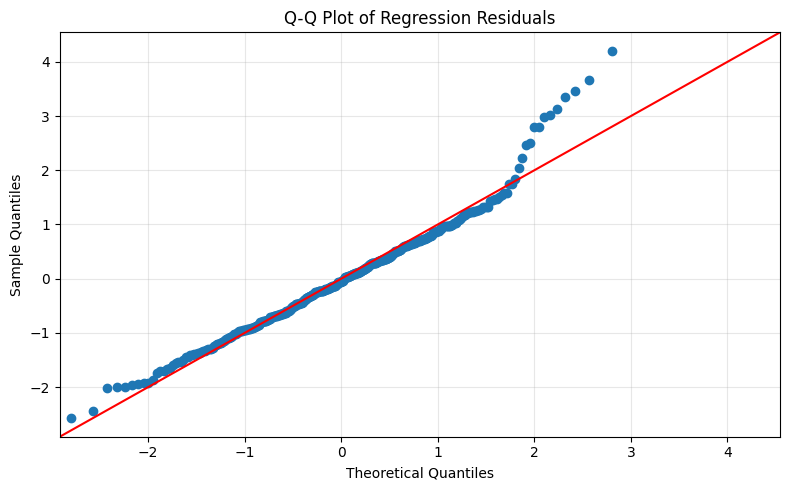

In [83]:
# Create a figure for the Q-Q plot
plt.figure(figsize=(8, 5))

# Generate a Q-Q plot of the regression residuals
sm.qqplot(
    residuals,
    line="45",
    fit=True,
    ax=plt.gca()
)

# Add a descriptive title
plt.title("Q-Q Plot of Regression Residuals")

# Label the horizontal axis
plt.xlabel("Theoretical Quantiles")

# Label the vertical axis
plt.ylabel("Sample Quantiles")

# Add gridlines for readability
plt.grid(True, alpha=0.3)

# Adjust spacing and display the plot
plt.tight_layout()
plt.show()

### Interpretation of Q-Q Plot

The Q-Q plot shows that most residuals in the middle of the
distribution follow the theoretical normal reference line.

However, noticeable deviations appear in the upper tail,
where several observations fall above the reference line.

This suggests that the residuals are not perfectly normally
distributed and may have a heavier right tail.

These findings are consistent with the normality test results
reported in the OLS regression summary.

Although the regression model explains approximately 80.8%
of the observed variation in MPG, departures from normality
should be considered when interpreting the statistical results.

### 12.3 Heteroscedasticity: Breusch-Pagan Test

### Purpose

The residual plot suggested that the spread of prediction
errors may change across fitted MPG values.

I will use the Breusch-Pagan test to investigate whether
the regression errors have constant variance.

### Hypotheses

- H0: The regression errors have constant variance.
- H1: The regression errors have nonconstant variance.

### Significance Level

Alpha = 0.05

If the p-value is less than 0.05, I will reject the null
hypothesis and conclude that there is statistical evidence
of heteroscedasticity.

If the p-value is at least 0.05, I will not reject the
null hypothesis.

In [84]:
# Import the Breusch-Pagan test
from statsmodels.stats.diagnostic import het_breuschpagan

# Perform the Breusch-Pagan test
# model.resid contains the regression residuals
# model.model.exog contains the predictors and intercept
bp_test = het_breuschpagan(
    model.resid,
    model.model.exog
)

# Store the test results
bp_results = pd.DataFrame({
    "Statistic": [
        "LM Statistic",
        "LM p-value",
        "F Statistic",
        "F p-value"
    ],
    "Value": bp_test
})

# Display the results
print("Breusch-Pagan Test Results:")
display(bp_results.round(6))

# Interpret the LM p-value
p_value = bp_test[1]

print("\nInterpretation:")

if p_value < 0.05:
    print("Reject H0: Evidence of heteroscedasticity.")
else:
    print("Fail to reject H0: Insufficient evidence of heteroscedasticity.")

Breusch-Pagan Test Results:


,Statistic,Value
0,LM Statistic,17.139554
1,LM p-value,0.000662
2,F Statistic,5.913442
3,F p-value,0.000593



Interpretation:
Reject H0: Evidence of heteroscedasticity.


### Interpretation of Breusch-Pagan Test

The Breusch-Pagan test produced an LM statistic of 17.1396
and a p-value of 0.000662.

Because the p-value is below the significance level of 0.05,
I reject the null hypothesis of constant error variance.

This provides statistical evidence of heteroscedasticity
in the multiple linear regression model.

The result is consistent with the residual plot, which
suggested that the spread of errors changes across
predicted MPG values.

Because heteroscedasticity can affect the reliability of
conventional OLS standard errors, p-values, and confidence
intervals, I will calculate HC3 heteroscedasticity-robust
standard errors as an additional analysis.

## 13. Heteroscedasticity-Robust Regression Inference

### 13.1 HC3 Robust Standard Errors

### Purpose
The Breusch-Pagan test found statistically significant
evidence of heteroscedasticity (p = 0.000662).

To account for nonconstant error variance, I will
calculate HC3 heteroscedasticity-robust standard errors
for the existing multiple linear regression model.

HC3 adjusts the estimated standard errors without
changing the fitted regression coefficients.

I will compare the robust p-values and confidence intervals
with the original OLS results.

This analysis will help determine whether my conclusions
about weight, horsepower, and model year remain consistent.

HC3 does not correct potential nonlinearity or other
model specification problems.

In [85]:
# Calculate HC3 heteroscedasticity-robust standard errors
# using the multiple linear regression model already fitted
robust_model = model.get_robustcov_results(cov_type="HC3")

# Display the complete regression summary with robust standard errors
print("Multiple Linear Regression with HC3 Robust Standard Errors:")
print(robust_model.summary())

Multiple Linear Regression with HC3 Robust Standard Errors:
                            OLS Regression Results                            
Dep. Variable:                    mpg   R-squared:                       0.808
Model:                            OLS   Adj. R-squared:                  0.807
Method:                 Least Squares   F-statistic:                     488.1
Date:                Wed, 25 Nov 2026   Prob (F-statistic):          2.78e-131
Time:                        17:46:51   Log-Likelihood:                -1037.4
No. Observations:                 392   AIC:                             2083.
Df Residuals:                     388   BIC:                             2099.
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------

### Interpretation of HC3 Robust Regression

The Breusch-Pagan test identified statistically significant
heteroscedasticity (p = 0.000662). Therefore, I recalculated
the regression standard errors using the HC3 robust method.

The regression coefficients and R-squared remained unchanged
(R-squared = 0.808).

Vehicle weight remained statistically significant
(coefficient = -0.0064, HC3 p < 0.001).

Horsepower remained statistically nonsignificant
(coefficient = -0.0050, HC3 p = 0.628).

Model year remained statistically significant
(coefficient = 0.7487, HC3 p < 0.001).

The main statistical conclusions are consistent between
the conventional OLS and HC3 robust results.

HC3 addresses heteroscedasticity in the standard errors,
but it does not correct possible nonlinearity or other
model-specification problems.

## 14. Actual vs. Predicted MPG

### Purpose

I will compare the actual MPG values with the MPG values
predicted by the multiple linear regression model.

This visualization will help me examine how closely the
fitted model describes the observed fuel efficiency.

- X-axis: Actual MPG
- Y-axis: Predicted MPG

A diagonal reference line represents perfect predictions.

Points close to the line indicate smaller prediction errors,
while points farther away indicate larger errors.

Because the model was fitted using these same observations,
this plot evaluates in-sample fit rather than performance
on new automobiles.

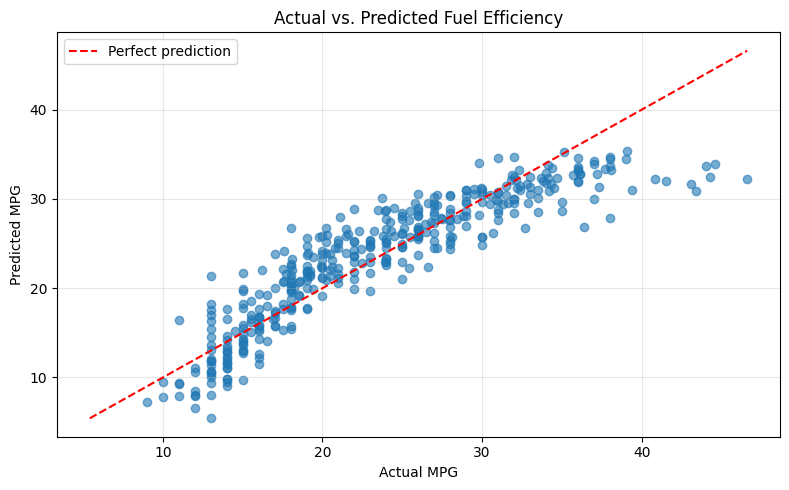

In [86]:
# Create a figure for comparing actual and predicted MPG
plt.figure(figsize=(8, 5))

# Plot actual MPG against predicted MPG
plt.scatter(
    y,
    predicted_mpg,
    alpha=0.6
)

# Find the minimum and maximum values for the reference line
min_mpg = min(y.min(), predicted_mpg.min())
max_mpg = max(y.max(), predicted_mpg.max())

# Draw a diagonal line representing perfect predictions
plt.plot(
    [min_mpg, max_mpg],
    [min_mpg, max_mpg],
    color="red",
    linestyle="--",
    label="Perfect prediction"
)

# Add a descriptive title
plt.title("Actual vs. Predicted Fuel Efficiency")

# Label the horizontal axis
plt.xlabel("Actual MPG")

# Label the vertical axis
plt.ylabel("Predicted MPG")

# Add gridlines for readability
plt.grid(True, alpha=0.3)

# Display the legend
plt.legend()

# Adjust spacing and display the plot
plt.tight_layout()
plt.show()

### Interpretation of Actual vs. Predicted MPG

The scatterplot shows that predicted MPG generally increases
as actual MPG increases.

Many observations are relatively close to the diagonal
reference line, indicating that the model captures much
of the variation in fuel efficiency.

This is consistent with the model's R-squared of 0.808.

However, some observations show substantial prediction errors.
In particular, the model tends to underestimate MPG for
several highly fuel-efficient automobiles.

This pattern is consistent with the earlier residual plot,
which suggested possible nonlinearity.

Because the model was evaluated on the same observations
used for fitting, these results describe in-sample fit
rather than predictive performance on new vehicles.

## 15. Model Prediction Error

### Purpose

I will calculate Mean Absolute Error (MAE) and
Root Mean Squared Error (RMSE) to summarize the
prediction errors of the multiple linear regression model.

MAE measures the average absolute difference between
actual and predicted MPG.

RMSE measures the square root of the average squared
prediction error, giving greater weight to larger errors.

Both metrics are expressed in MPG.

Because these metrics are calculated using the same
392 observations used to fit the model, they describe
in-sample prediction error.

In [87]:
# Calculate the absolute difference between actual and predicted MPG
absolute_errors = abs(y - predicted_mpg)

# Calculate Mean Absolute Error (MAE)
mae = absolute_errors.mean()

# Calculate the squared prediction errors
squared_errors = (y - predicted_mpg) ** 2

# Calculate Root Mean Squared Error (RMSE)
rmse = np.sqrt(squared_errors.mean())

# Display the results
print("Model Prediction Error:")
print(f"Mean Absolute Error (MAE): {mae:.3f} MPG")
print(f"Root Mean Squared Error (RMSE): {rmse:.3f} MPG")
print(f"R-squared: {model.rsquared:.3f}")

Model Prediction Error:
Mean Absolute Error (MAE): 2.614 MPG
Root Mean Squared Error (RMSE): 3.413 MPG
R-squared: 0.808


### Interpretation of Model Prediction Error

The multiple linear regression model produced a Mean Absolute
Error (MAE) of 2.614 MPG and a Root Mean Squared Error (RMSE)
of 3.413 MPG.

The MAE indicates that the model's predictions differ from
the actual MPG values by approximately 2.61 MPG on average.

The RMSE is higher than the MAE because it gives greater
weight to larger prediction errors.

The model's R-squared is 0.808, indicating that weight,
horsepower, and model year together explain approximately
80.8% of the observed variation in MPG.

Although the model provides a reasonably strong in-sample fit,
the residual diagnostics revealed possible nonlinearity
and statistically significant heteroscedasticity.

These prediction error metrics were calculated using the
same observations used to fit the model and should not be
interpreted as out-of-sample predictive performance.

## 16. Exploratory Model Comparison

### Purpose

The original multiple linear regression model includes
vehicle weight, horsepower, and model year.

However, horsepower was not statistically significant
after controlling for the other predictors.

Additionally, weight and horsepower were strongly
correlated (r = 0.865).

I will fit a reduced regression model using only
weight and model year.

I will compare the original and reduced models using
R-squared, adjusted R-squared, and AIC.

This exploratory analysis will help assess whether
including horsepower meaningfully improves model fit.

The original three-predictor model will remain the
primary analysis.

In [88]:
# Define the predictors for the reduced regression model
# Horsepower is excluded for this exploratory comparison
X_reduced = clean_df[["weight", "model year"]]

# Add an intercept to the reduced model
X_reduced = sm.add_constant(X_reduced)

# Fit the reduced multiple linear regression model
reduced_model = sm.OLS(y, X_reduced).fit()

# Compare the original and reduced regression models
comparison = pd.DataFrame({
    "Model": [
        "Original: Weight + Horsepower + Model Year",
        "Reduced: Weight + Model Year"
    ],
    "R-squared": [
        model.rsquared,
        reduced_model.rsquared
    ],
    "Adjusted R-squared": [
        model.rsquared_adj,
        reduced_model.rsquared_adj
    ],
    "AIC": [
        model.aic,
        reduced_model.aic
    ]
})

# Display the comparison rounded to three decimal places
print("Comparison of Original and Reduced Regression Models:")
display(comparison.round(3))

Comparison of Original and Reduced Regression Models:


,Model,R-squared,Adjusted R-squared,AIC
0,Original: Weight + Horsepower + Model Year,0.808,0.807,2082.829
1,Reduced: Weight + Model Year,0.808,0.807,2081.113


### Interpretation of Model Comparison

The original regression model included weight, horsepower,
and model year, while the reduced model included only
weight and model year.

Both models explained approximately 80.8% of the observed
variation in MPG (R-squared = 0.808).

The adjusted R-squared values were also nearly identical
(approximately 0.807).

The reduced model had a slightly lower AIC (2081.113)
than the original model (2082.829). However, the AIC
difference was small (1.716).

These results suggest that horsepower adds little
additional explanatory value after accounting for
vehicle weight and model year.

This is consistent with the nonsignificant horsepower
coefficient in the original regression and the strong
correlation between weight and horsepower.

I will retain the original three-predictor model as
the primary analysis and report the reduced model as
an exploratory comparison.

### 16.1 Partial F-Test for Horsepower

### Purpose

I will perform a partial F-test to compare the original
three-predictor model with the reduced two-predictor model.

The goal is to determine whether including horsepower
significantly improves model fit after accounting for
vehicle weight and model year.

### Hypotheses

- H0: The horsepower regression coefficient equals zero.
- H1: The horsepower regression coefficient is not zero.

### Significance Level

Alpha = 0.05

A p-value below 0.05 would indicate that adding horsepower
significantly improves the model under the conventional
OLS assumptions.

Because heteroscedasticity was detected earlier, I will
interpret this test as supplementary and use HC3 robust
inference for my primary conclusions.

In [89]:
# Compare the original model with the reduced model
# using a classical partial F-test
f_statistic, p_value, df_difference = model.compare_f_test(
    reduced_model
)

# Display the partial F-test results
print("Partial F-Test: Does Horsepower Improve the Model?")
print(f"F-statistic: {f_statistic:.4f}")
print(f"p-value: {p_value:.4f}")
print(f"Difference in model degrees of freedom: {df_difference:.0f}")

# Interpret the p-value using alpha = 0.05
print("\nInterpretation:")

if p_value < 0.05:
    print("Reject H0: Horsepower significantly improves model fit.")
else:
    print("Fail to reject H0: No statistically significant improvement from adding horsepower.")

Partial F-Test: Does Horsepower Improve the Model?
F-statistic: 0.2806
p-value: 0.5966
Difference in model degrees of freedom: 1

Interpretation:
Fail to reject H0: No statistically significant improvement from adding horsepower.


### Interpretation of Partial F-Test

The partial F-test compared the original three-predictor
regression model with the reduced model excluding horsepower.

The test produced an F-statistic of 0.2806 and a
p-value of 0.5966.

Because the p-value is greater than 0.05, I fail to reject
the null hypothesis that the horsepower coefficient is zero.

This indicates that adding horsepower does not provide a
statistically significant improvement in model fit after
accounting for vehicle weight and model year.

This finding is consistent with the original OLS regression
(p = 0.597) and HC3 robust regression (p = 0.628).

Because heteroscedasticity was detected, the classical
partial F-test is considered supplementary, while the
HC3 robust results provide the primary statistical inference.

The original three-predictor model remains the primary
analysis because it directly addresses the research question.

## 17. Conclusion

### Research Question
How are vehicle weight, horsepower, and model year associated
with fuel efficiency (MPG)?

### Main Findings

This study analyzed 392 automobiles from the Auto MPG dataset
using multiple linear regression.

The regression model explained approximately 80.8% of the
observed variation in MPG (R-squared = 0.808).

Vehicle weight had a statistically significant negative
association with MPG. Holding horsepower and model year
constant, an additional 1,000 pounds of vehicle weight
was associated with approximately 6.4 fewer MPG
(HC3 p < 0.001).

Model year had a statistically significant positive
association with MPG. Holding weight and horsepower constant,
each additional model year was associated with approximately
0.75 higher MPG (HC3 p < 0.001).

Horsepower was strongly negatively correlated with MPG
(r = -0.778), but its coefficient was not statistically
significant after controlling for weight and model year
(HC3 p = 0.628).

A supplementary model comparison showed that removing
horsepower produced almost no change in R-squared.

### Model Limitations

Residual diagnostics suggested possible nonlinearity
and departures from normality.

The Breusch-Pagan test also identified statistically
significant heteroscedasticity (p = 0.000662).

HC3 robust standard errors were used to address
heteroscedasticity in the regression inference.

However, HC3 does not correct potential nonlinearity
or other model-specification problems.

The dataset includes historical automobiles from
1970 to 1982, so the findings should not be generalized
automatically to modern vehicles.

The analysis identifies statistical associations
rather than causal relationships.

### Final Conclusion

Vehicle weight and model year were significantly associated
with fuel efficiency in the multiple regression model.

Horsepower did not provide a statistically significant
additional association after accounting for the other
predictors.

These findings demonstrate how multiple linear regression
can be used to investigate relationships among automotive
characteristics while accounting for multiple variables.

## 18. Verification Appendix

### 18.1 Verification Check 1: Hand-Scale Trace

#### Purpose

I will select 10 observations from the cleaned Auto MPG
dataset and manually verify statistical calculations.

I will compare the manually calculated mean MPG with
Python's result and trace the selected observations
through the fitted regression model.

This check will help verify the accuracy of the
calculations used in the analysis.

In [90]:
# Select the first 10 observations from the cleaned dataset
verification_sample = clean_df.head(10).copy()

# Display the selected observations
print("Selected observations for hand-scale verification:")
display(verification_sample)

# Confirm the sample size
print("Number of selected observations:", len(verification_sample))

Selected observations for hand-scale verification:


,mpg,weight,horsepower,model year
0,18.0,3504,130.0,70
1,15.0,3693,165.0,70
2,18.0,3436,150.0,70
3,16.0,3433,150.0,70
4,17.0,3449,140.0,70
5,15.0,4341,198.0,70
6,14.0,4354,220.0,70
7,14.0,4312,215.0,70
8,14.0,4425,225.0,70
9,15.0,3850,190.0,70


Number of selected observations: 10



#### Manual Calculation of Mean MPG

The MPG values for the first 10 observations are:

18, 15, 18, 16, 17, 15, 14, 14, 14, 15.

Manual calculation:

- Sum of MPG values = 156
- Number of observations = 10
- Mean MPG = 156 / 10 = 15.6

The manually calculated mean MPG is 15.6.

I will compare this result with the mean calculated
using Python to verify the accuracy of the calculation.


In [91]:

# Manually calculated mean MPG
manual_mean = 156 / 10

# Calculate mean MPG using Python
python_mean = verification_sample["mpg"].mean()

# Calculate the absolute difference
difference = abs(manual_mean - python_mean)

# Display verification results
print(f"Manual mean MPG: {manual_mean:.4f}")
print(f"Python mean MPG: {python_mean:.4f}")
print(f"Absolute difference: {difference:.4f}")

# Verify whether the results match
if np.isclose(manual_mean, python_mean):
    print("Verification PASSED: Both results match.")
else:
    print("Verification FAILED: Results do not match.")


Manual mean MPG: 15.6000
Python mean MPG: 15.6000
Absolute difference: 0.0000
Verification PASSED: Both results match.



#### Verification of Regression Predictions and Residuals

To further verify the regression analysis, I will calculate
predicted MPG and residuals for the 10 selected automobiles
using the regression equation.

The first automobile has the following characteristics:

- Actual MPG: 18
- Weight: 3504 pounds
- Horsepower: 130
- Model year: 70

Using the rounded regression coefficients:

Predicted MPG = -13.7194 - 0.0064(3504)
                - 0.0050(130) + 0.7487(70)

Predicted MPG = 15.614

Residual = Actual MPG - Predicted MPG

Residual = 18 - 15.614 = 2.386

I will compare predictions calculated using the rounded
coefficients with the original regression model predictions.
Small differences may occur due to coefficient rounding.


In [92]:

# Create a separate dataframe for regression verification
trace_df = verification_sample.copy()

# Calculate predictions using rounded regression coefficients
trace_df["manual_predicted_mpg"] = (
    -13.7194
    - 0.0064 * trace_df["weight"]
    - 0.0050 * trace_df["horsepower"]
    + 0.7487 * trace_df["model year"]
)

# Obtain predictions from the original fitted model
trace_df["model_predicted_mpg"] = model.fittedvalues.loc[
    trace_df.index
]

# Calculate residuals
trace_df["manual_residual"] = (
    trace_df["mpg"] - trace_df["manual_predicted_mpg"]
)

trace_df["model_residual"] = model.resid.loc[
    trace_df.index
]

# Calculate absolute prediction differences
trace_df["absolute_difference"] = abs(
    trace_df["manual_predicted_mpg"]
    - trace_df["model_predicted_mpg"]
)

# Display the verification results
display(trace_df.round(4))

# Report the maximum prediction difference
print(
    "Maximum absolute difference:",
    round(trace_df["absolute_difference"].max(), 4)
)


,mpg,weight,horsepower,model year,manual_predicted_mpg,model_predicted_mpg,manual_residual,model_residual,absolute_difference
0,18.0,3504,130.0,70,15.6140,15.4471,2.3860,2.5529,0.1669
1,15.0,3693,165.0,70,14.2294,14.0535,0.7706,0.9465,0.1759
2,18.0,3436,150.0,70,15.9492,15.7856,2.0508,2.2144,0.1636
3,16.0,3433,150.0,70,15.9684,15.8049,0.0316,0.1951,0.1635
4,17.0,3449,140.0,70,15.9160,15.7518,1.0840,1.2482,0.1642
5,15.0,4341,198.0,70,9.9172,9.7104,5.0828,5.2896,0.2068
6,14.0,4354,220.0,70,9.7240,9.5166,4.2760,4.4834,0.2074
7,14.0,4312,215.0,70,10.0178,9.8124,3.9822,4.1876,0.2054
8,14.0,4425,225.0,70,9.2446,9.0338,4.7554,4.9662,0.2108
9,15.0,3850,190.0,70,13.0996,12.9162,1.9004,2.0838,0.1834


Maximum absolute difference: 0.2108



#### Investigating the Prediction Discrepancy

The predictions calculated using rounded regression
coefficients did not exactly match the original model
predictions.

For the first automobile:

- Prediction using rounded coefficients: 15.6140 MPG
- Original model prediction: 15.4471 MPG
- Absolute difference: 0.1669 MPG

The maximum absolute prediction difference across the
10 selected observations was 0.2108 MPG.

I suspect that rounding the regression coefficients
caused this discrepancy. To investigate, I will
recalculate the predictions using the full-precision
coefficients from the fitted regression model.


In [93]:

# Extract full-precision regression coefficients
coefficients = model.params

print("Full-precision regression coefficients:")

for name, value in coefficients.items():
    print(f"{name}: {value:.15f}")

# Recalculate predictions using full-precision coefficients
trace_df["full_precision_prediction"] = (
    coefficients["const"]
    + coefficients["weight"] * trace_df["weight"]
    + coefficients["horsepower"] * trace_df["horsepower"]
    + coefficients["model year"] * trace_df["model year"]
)

# Recalculate residuals
trace_df["full_precision_residual"] = (
    trace_df["mpg"] - trace_df["full_precision_prediction"]
)

# Calculate prediction differences
trace_df["corrected_difference"] = abs(
    trace_df["full_precision_prediction"]
    - trace_df["model_predicted_mpg"]
)

# Display comparison
display(trace_df[[
    "mpg",
    "manual_predicted_mpg",
    "model_predicted_mpg",
    "full_precision_prediction",
    "corrected_difference"
]].round(6))

# Compare differences before and after correction
print(
    "Maximum difference before correction:",
    round(trace_df["absolute_difference"].max(), 6)
)

print(
    "Maximum difference after correction:",
    round(trace_df["corrected_difference"].max(), 10)
)

# Verify predictions and residuals
predictions_match = np.allclose(
    trace_df["full_precision_prediction"],
    trace_df["model_predicted_mpg"]
)

residuals_match = np.allclose(
    trace_df["full_precision_residual"],
    trace_df["model_residual"]
)

print("Predictions match:", predictions_match)
print("Residuals match:", residuals_match)

if predictions_match and residuals_match:
    print("Verification PASSED: Discrepancy resolved.")
else:
    print("Verification FAILED: Further investigation needed.")


Full-precision regression coefficients:
const: -13.719360032901342
weight: -0.006447746217825
horsepower: -0.004999767121331
model year: 0.748705103484975


,mpg,manual_predicted_mpg,model_predicted_mpg,full_precision_prediction,corrected_difference
0,18.0,15.6140,15.447125,15.447125,0.0
1,15.0,14.2294,14.053509,14.053509,0.0
2,18.0,15.9492,15.785576,15.785576,0.0
3,16.0,15.9684,15.804919,15.804919,0.0
4,17.0,15.9160,15.751753,15.751753,0.0
5,15.0,9.9172,9.710377,9.710377,0.0
6,14.0,9.7240,9.516561,9.516561,0.0
7,14.0,10.0178,9.812366,9.812366,0.0
8,14.0,9.2446,9.033773,9.033773,0.0
9,15.0,13.0996,12.916219,12.916219,0.0


Maximum difference before correction: 0.210827
Maximum difference after correction: 0.0
Predictions match: True
Residuals match: True
Verification PASSED: Discrepancy resolved.



#### Hand-Scale Trace: Final Findings

I selected the first 10 observations from the cleaned
dataset to verify my statistical calculations.

The manually calculated mean MPG was 15.6, which
matched the Python result exactly.

When I calculated regression predictions using rounded
coefficients, I found a maximum difference of
0.210827 MPG compared with the original model.

I investigated this discrepancy by using the
full-precision regression coefficients. After
recalculating the predictions and residuals, the
difference was zero at the reported numerical precision.

This verification confirmed the accuracy of the mean,
prediction, and residual calculations for the selected
observations.

All 10 automobiles were from model year 1970.
Therefore, this check verifies calculation accuracy
rather than the validity of the overall regression model.



### 18.2 Verification Check 2: Error Audit

#### Purpose

The purpose of this error audit is to identify potential
errors in data preparation, statistical analysis, and
interpretation.

The audit will examine:

- Sample size and denominators
- Missing values and excluded observations
- Confounding and multicollinearity
- Statistical interpretation
- Causal language

#### Audit 1: Sample Size and Excluded Observations

I will verify the original sample size, the number of
excluded observations, and the final sample size used
in the regression model.

I will also calculate the percentage of excluded
observations and confirm that the regression model
uses the correct number of records.


In [94]:

# Original number of observations
original_n = len(df)

# Number of observations after cleaning
cleaned_n = len(clean_df)

# Number of excluded observations
excluded_n = original_n - cleaned_n

# Percentage of excluded observations
excluded_pct = (excluded_n / original_n) * 100

# Percentage of retained observations
retained_pct = (cleaned_n / original_n) * 100

# Number of observations used in regression
regression_n = int(model.nobs)

# Count remaining missing values
remaining_missing = clean_df.isna().sum().sum()

# Display audit results
print("AUDIT 1: SAMPLE SIZE AND EXCLUDED OBSERVATIONS")
print("-" * 50)

print(f"Original observations: {original_n}")
print(f"Excluded observations: {excluded_n}")
print(f"Cleaned observations: {cleaned_n}")
print(f"Excluded percentage: {excluded_pct:.2f}%")
print(f"Retained percentage: {retained_pct:.2f}%")
print(f"Regression observations: {regression_n}")
print(f"Remaining missing values: {remaining_missing}")

# Verify consistency
assert original_n == cleaned_n + excluded_n
assert cleaned_n == regression_n
assert remaining_missing == 0

print("\nAudit PASSED: Sample sizes are consistent.")


AUDIT 1: SAMPLE SIZE AND EXCLUDED OBSERVATIONS
--------------------------------------------------
Original observations: 398
Excluded observations: 6
Cleaned observations: 392
Excluded percentage: 1.51%
Retained percentage: 98.49%
Regression observations: 392
Remaining missing values: 0

Audit PASSED: Sample sizes are consistent.



#### Audit 2: Missing Values and Exclusion Decisions

The original dataset contained 398 observations,
and 392 observations remained after data cleaning.

I will investigate the six excluded records to confirm
that they contained missing horsepower values.

I will also verify that no complete observations were
unnecessarily excluded from the regression analysis.

Finally, I will examine the potential limitations
of excluding records with missing values.


In [95]:

# Identify missing or non-numeric horsepower values
horsepower_numeric = pd.to_numeric(
    df["horsepower"], errors="coerce"
)

# Identify records with missing horsepower
missing_hp_mask = horsepower_numeric.isna()

# Extract excluded records
excluded_records = df.loc[missing_hp_mask].copy()

# Display excluded records
print("AUDIT 2: MISSING VALUES AND EXCLUSION DECISIONS")
print("-" * 50)

print("Records with missing horsepower:",
      missing_hp_mask.sum())

display(excluded_records)

# Identify complete records for the selected variables
audit_df = df[
    ["mpg", "weight", "horsepower", "model year"]
].copy()

audit_df["horsepower"] = horsepower_numeric

expected_clean_df = audit_df.dropna()

# Verify that the cleaned dataset contains
# exactly the expected complete observations
pd.testing.assert_frame_equal(
    expected_clean_df.reset_index(drop=True),
    clean_df.reset_index(drop=True),
    check_dtype=False
)

assert len(excluded_records) == excluded_n

print("\nExpected complete records:", len(expected_clean_df))
print("Actual cleaned records:", len(clean_df))

print("\nAudit PASSED: The cleaned dataset matches")
print("the expected complete observations.")


AUDIT 2: MISSING VALUES AND EXCLUSION DECISIONS
--------------------------------------------------
Records with missing horsepower: 6


,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
32,25.0,4,98.0,?,2046,19.0,71,1,ford pinto
126,21.0,6,200.0,?,2875,17.0,74,1,ford maverick
330,40.9,4,85.0,?,1835,17.3,80,2,renault lecar deluxe
336,23.6,4,140.0,?,2905,14.3,80,1,ford mustang cobra
354,34.5,4,100.0,?,2320,15.8,81,2,renault 18i
374,23.0,4,151.0,?,3035,20.5,82,1,amc concord dl



Expected complete records: 392
Actual cleaned records: 392

Audit PASSED: The cleaned dataset matches
the expected complete observations.



#### Audit 3: Confounding and Multicollinearity

The previous audit confirmed that all six excluded
records contained missing horsepower values. No complete
observations were unnecessarily removed.

However, four of the six excluded automobiles were
from model years 1980–1982. Therefore, the possibility
of selection bias cannot be ruled out.

In this audit, I will compare the relationship between
horsepower and MPG before and after controlling for
vehicle weight and model year.

I will examine the regression coefficients, p-values,
correlation, and variance inflation factors to avoid
misinterpreting the association between horsepower
and fuel efficiency.


In [96]:

# Fit a simple regression using horsepower only
X_hp = sm.add_constant(clean_df[["horsepower"]])

hp_only_model = sm.OLS(
    clean_df["mpg"], X_hp
).fit(cov_type="HC3")

# Obtain robust results from the multiple regression
adjusted_model = model.get_robustcov_results(
    cov_type="HC3"
)

# Identify the position of horsepower in the model
hp_index = model.model.exog_names.index("horsepower")

# Compare unadjusted and adjusted results
audit_comparison = pd.DataFrame({
    "Model": [
        "Horsepower only",
        "Weight + Horsepower + Model Year"
    ],
    "Horsepower coefficient": [
        hp_only_model.params["horsepower"],
        adjusted_model.params[hp_index]
    ],
    "HC3 p-value": [
        hp_only_model.pvalues["horsepower"],
        adjusted_model.pvalues[hp_index]
    ],
    "R-squared": [
        hp_only_model.rsquared,
        adjusted_model.rsquared
    ]
})

print("AUDIT 3: CONFOUNDING AND MULTICOLLINEARITY")
print("-" * 50)

display(audit_comparison.round(6))

# Calculate correlation between weight and horsepower
hp_weight_corr = clean_df["horsepower"].corr(
    clean_df["weight"]
)

print(f"Weight-horsepower correlation: {hp_weight_corr:.4f}")

# Calculate VIF for each predictor
from statsmodels.stats.outliers_influence import (
    variance_inflation_factor
)

audit_X = sm.add_constant(
    clean_df[["weight", "horsepower", "model year"]]
)

audit_vif = pd.DataFrame({
    "Variable": audit_X.columns,
    "VIF": [
        variance_inflation_factor(audit_X.values, i)
        for i in range(audit_X.shape[1])
    ]
})

print("\nVariance Inflation Factors:")
display(
    audit_vif[audit_vif["Variable"] != "const"].round(4)
)


AUDIT 3: CONFOUNDING AND MULTICOLLINEARITY
--------------------------------------------------


,Model,Horsepower coefficient,HC3 p-value,R-squared
0,Horsepower only,-0.157845,0.00000,0.605948
1,Weight + Horsepower + Model Year,-0.005000,0.62826,0.808319


Weight-horsepower correlation: 0.8645

Variance Inflation Factors:


,Variable,VIF
1,weight,4.0089
2,horsepower,4.3862
3,model year,1.2249



#### Audit 4: Statistical Interpretation

The confounding and multicollinearity audit showed
that horsepower had a strong negative association
with MPG when examined alone.

However, its coefficient decreased substantially
after controlling for weight and model year.
The adjusted association was not statistically
significant (HC3 p = 0.62826).

I will now verify the regression effect sizes,
95% confidence intervals, and HC3 robust p-values.

To improve practical interpretation, I will report
the estimated MPG differences associated with:

- A 1,000-pound increase in vehicle weight
- A 100-horsepower increase in engine horsepower
- A one-year increase in model year

All adjusted associations will be interpreted while
holding the other predictors constant.


In [97]:

# Obtain HC3 robust regression results
audit_robust = model.get_robustcov_results(
    cov_type="HC3"
)

# Extract regression statistics
variable_names = model.model.exog_names
confidence_intervals = audit_robust.conf_int(alpha=0.05)

# Create a regression results table
audit_results = pd.DataFrame({
    "Variable": variable_names,
    "Coefficient": audit_robust.params,
    "HC3 Standard Error": audit_robust.bse,
    "HC3 p-value": audit_robust.pvalues,
    "CI Lower": confidence_intervals[:, 0],
    "CI Upper": confidence_intervals[:, 1]
})

# Exclude the intercept from practical interpretation
audit_results = audit_results[
    audit_results["Variable"] != "const"
].copy()

# Define meaningful units
scale_factors = {
    "weight": 1000,
    "horsepower": 100,
    "model year": 1
}

audit_results["Unit Increase"] = (
    audit_results["Variable"].map(scale_factors)
)

# Calculate practical effect sizes
audit_results["MPG Difference"] = (
    audit_results["Coefficient"]
    * audit_results["Unit Increase"]
)

# Scale confidence intervals
audit_results["Scaled CI Lower"] = (
    audit_results["CI Lower"]
    * audit_results["Unit Increase"]
)

audit_results["Scaled CI Upper"] = (
    audit_results["CI Upper"]
    * audit_results["Unit Increase"]
)

# Determine statistical significance
audit_results["Significant"] = (
    audit_results["HC3 p-value"] < 0.05
)

print("AUDIT 4: STATISTICAL INTERPRETATION")
print("-" * 50)

# Display practical interpretation table
display(audit_results[[
    "Variable",
    "Unit Increase",
    "MPG Difference",
    "Scaled CI Lower",
    "Scaled CI Upper",
    "HC3 p-value",
    "Significant"
]].round(6))

# Verify consistency between p-values
# and 95% confidence intervals
ci_excludes_zero = (
    (audit_results["Scaled CI Lower"] > 0)
    | (audit_results["Scaled CI Upper"] < 0)
)

assert (
    ci_excludes_zero == audit_results["Significant"]
).all()

print(f"\nR-squared: {model.rsquared:.6f}")
print(f"Adjusted R-squared: {model.rsquared_adj:.6f}")
print(f"Number of observations: {int(model.nobs)}")

print("\nAudit PASSED: Confidence intervals and")
print("statistical significance are consistent.")


AUDIT 4: STATISTICAL INTERPRETATION
--------------------------------------------------


,Variable,Unit Increase,MPG Difference,Scaled CI Lower,Scaled CI Upper,HC3 p-value,Significant
1,weight,1000,-6.447746,-7.287819,-5.607673,0.00000,True
2,horsepower,100,-0.499977,-2.528616,1.528663,0.62826,False
3,model year,1,0.748705,0.650684,0.846726,0.00000,True



R-squared: 0.808319
Adjusted R-squared: 0.806837
Number of observations: 392

Audit PASSED: Confidence intervals and
statistical significance are consistent.



#### Audit 5: Causal Language and Model Limitations

The Auto MPG dataset contains observational data.
Therefore, the regression results describe statistical
associations rather than causal relationships.

I reviewed the interpretation of the regression results
to avoid unsupported conclusions.

The following interpretation rules will be applied:

- Higher vehicle weight is associated with lower MPG,
  rather than causing lower MPG.

- Horsepower is not statistically significant after
  controlling for weight and model year. This does not
  establish that horsepower has no relationship with MPG.

- Later model years are associated with higher MPG.

- R-squared represents the proportion of observed
  variation in MPG explained by the model, not
  prediction accuracy.

**Model Limitations**

- The dataset contains automobiles from 1970–1982,
  limiting generalization to modern vehicles.

- Six observations were excluded because of missing
  horsepower values. Potential selection bias remains.

- Weight and horsepower are strongly correlated,
  making their individual associations harder to separate.

- The residual plots suggest possible nonlinearity
  and departures from normality.

- The Breusch-Pagan test identified heteroscedasticity.

- HC3 robust standard errors address heteroscedasticity
  in statistical inference but do not correct nonlinearity
  or other forms of model misspecification.

- The reported prediction errors were calculated
  using the training data and do not establish
  out-of-sample predictive performance.

- Other vehicle characteristics, such as engine
  displacement and number of cylinders, may influence
  the estimated associations.
